In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df = pd.read_csv("/content/Healthcare_Preprocessing_Demo.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
df.head()
df.tail()
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Columns in the dataset:")
print(df.columns.tolist())
df.info()
df.describe()

Number of rows: 25005
Number of columns: 6
Columns in the dataset:
['Patient_ID', 'Age', 'Gender', 'Symptoms', 'Symptom_Count', 'Disease']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25005 entries, 0 to 25004
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Patient_ID     25005 non-null  int64  
 1   Age            25003 non-null  float64
 2   Gender         25003 non-null  object 
 3   Symptoms       25003 non-null  object 
 4   Symptom_Count  25004 non-null  float64
 5   Disease        25004 non-null  object 
dtypes: float64(2), int64(1), object(3)
memory usage: 1.1+ MB


,Patient_ID,Age,Symptom_Count
count,25005.000000,25003.000000,25004.00000
mean,12499.451310,45.304004,5.00156
std,7217.411867,26.103716,1.41581
min,1.000000,1.000000,3.00000
25%,6249.000000,23.000000,4.00000
50%,12499.000000,45.000000,5.00000
75%,18750.000000,68.000000,6.00000
max,25000.000000,90.000000,7.00000


In [ ]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)
duplicates = df[df.duplicated(keep=False)]

duplicates


Missing values in each column:
Patient_ID       0
Age              2
Gender           2
Symptoms         2
Symptom_Count    1
Disease          1
dtype: int64
Missing values in each column:
Patient_ID       0
Age              2
Gender           2
Symptoms         2
Symptom_Count    1
Disease          1
dtype: int64


,Patient_ID,Age,Gender,Symptoms,Symptom_Count,Disease
25,26,40.0,Female,"muscle pain, vomiting, weight loss, swelling, ...",7.0,Dermatitis
1250,1251,25.0,Male,"sneezing, sore throat, dizziness, headache, bl...",7.0,Stroke
5000,5001,48.0,Other,"swelling, depression, diarrhea, sore throat, a...",6.0,Food Poisoning
10000,10001,63.0,Male,"runny nose, headache, dizziness, appetite loss",4.0,Liver Disease
20000,20001,27.0,Other,"blurred vision, swelling, chest pain, weight g...",5.0,Epilepsy
25000,26,40.0,Female,"muscle pain, vomiting, weight loss, swelling, ...",7.0,Dermatitis
25001,1251,25.0,Male,"sneezing, sore throat, dizziness, headache, bl...",7.0,Stroke
25002,5001,48.0,Other,"swelling, depression, diarrhea, sore throat, a...",6.0,Food Poisoning
25003,10001,63.0,Male,"runny nose, headache, dizziness, appetite loss",4.0,Liver Disease
25004,20001,27.0,Other,"blurred vision, swelling, chest pain, weight g...",5.0,Epilepsy


In [ ]:
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Gender"] = df["Gender"].fillna(df["Gender"].mode()[0])
df = df.dropna(subset=["Symptoms"])
df = df.dropna(subset=["Disease"])
df = df.drop_duplicates()

print("Duplicate records after cleaning:", df.duplicated().sum())
df = df.drop_duplicates()


Duplicate records after cleaning: 0


In [ ]:
df["Gender"] = df["Gender"].astype(str).str.strip().str.title()

df["Symptoms"] = df["Symptoms"].astype(str).str.strip().str.lower()

df["Disease"] = df["Disease"].astype(str).str.strip()
df["Symptom_Count"] = df["Symptoms"].apply(
    lambda x: len([s.strip() for s in x.split(",") if s.strip()])
)
df[["Symptoms", "Symptom_Count"]].head()
print("Missing values after preprocessing:")
print(df.isnull().sum())

print("\nDuplicate records after preprocessing:")
print(df.duplicated().sum())

print("\nFinal dataset shape:")
print(df.shape)

Missing values after preprocessing:
Patient_ID       0
Age              0
Gender           0
Symptoms         0
Symptom_Count    0
Disease          0
dtype: int64

Duplicate records after preprocessing:
0

Final dataset shape:
(24997, 6)


In [ ]:
#DISEASE FREQUENCY
disease_counts = df["Disease"].value_counts()
print(disease_counts)

Disease
Anxiety                   911
Arthritis                 896
Food Poisoning            871
Depression                859
Allergy                   858
Bronchitis                856
Dermatitis                856
Thyroid Disorder          855
Migraine                  854
Diabetes                  850
COVID-19                  839
Hypertension              833
Epilepsy                  832
Ulcer                     832
Liver Disease             830
IBS                       830
Pneumonia                 829
Parkinson's               826
Influenza                 824
Dementia                  823
Obesity                   818
Tuberculosis              814
Anemia                    814
Chronic Kidney Disease    807
Common Cold               805
Heart Disease             804
Gastritis                 804
Sinusitis                 795
Stroke                    790
Asthma                    782
Name: count, dtype: int64


In [ ]:
#MOST COMMON DISEASE
most_common_disease = disease_counts.idxmax()
most_common_count = disease_counts.max()

print("Most common disease:", most_common_disease)
print("Number of records:", most_common_count)

Most common disease: Anxiety
Number of records: 911


In [ ]:
# least common disease
least_common_disease = disease_counts.idxmin()
least_common_count = disease_counts.min()

print("Least common disease:", least_common_disease)
print("Number of records:", least_common_count)

Least common disease: Asthma
Number of records: 782


In [ ]:
#number of disease
print("Total number of diseases:", df["Disease"].nunique())

Total number of diseases: 30


In [ ]:
#gender analysis
gender_counts = df["Gender"].value_counts()

print(gender_counts)

Gender
Other     8394
Female    8334
Male      8269
Name: count, dtype: int64


In [ ]:
# average age
average_age = df["Age"].mean()

print("Average patient age:", round(average_age, 2))

Average patient age: 45.3


In [ ]:
#minimum and maximum age
print("Minimum age:", df["Age"].min())
print("Maximum age:", df["Age"].max())

Minimum age: 1.0
Maximum age: 90.0


In [ ]:
# symptom count analysis
print(df["Symptom_Count"].describe())

count    24997.000000
mean         5.001440
std          1.415768
min          3.000000
25%          4.000000
50%          5.000000
75%          6.000000
max          7.000000
Name: Symptom_Count, dtype: float64


module 4 (pandas operations)

In [ ]:
# filtering
older_patients = df[df["Age"] > 60]

older_patients.head()

,Patient_ID,Age,Gender,Symptoms,Symptom_Count,Disease
1,2,76.0,Female,"insomnia, back pain, weight loss",3,Thyroid Disorder
2,3,78.0,Male,"sore throat, vomiting, diarrhea",3,Influenza
6,7,69.0,Male,"anxiety, shortness of breath, appetite loss, c...",5,Food Poisoning
10,11,78.0,Other,"vomiting, insomnia, shortness of breath, blurr...",5,Food Poisoning
11,12,72.0,Male,"back pain, diarrhea, nausea, runny nose, joint...",7,Diabetes


In [ ]:
# sorting
sorted_age = df.sort_values(by="Age", ascending=False)

sorted_age.head()

,Patient_ID,Age,Gender,Symptoms,Symptom_Count,Disease
24050,24051,90.0,Female,"depression, back pain, weight gain, vomiting, ...",5,Asthma
4035,4036,90.0,Other,"appetite loss, depression, shortness of breath...",7,Ulcer
1135,1136,90.0,Other,"insomnia, nausea, muscle pain",3,Common Cold
24091,24092,90.0,Female,"muscle pain, vomiting, runny nose, insomnia, w...",7,Food Poisoning
1435,1436,90.0,Other,"dizziness, anxiety, sneezing",3,Gastritis


In [ ]:
# add a new column
def age_group(age):
    if age < 18:
        return "Below 18"
    elif age < 40:
        return "18-39"
    elif age < 60:
        return "40-59"
    else:
        return "60+"

df["Age_Group"] = df["Age"].apply(age_group)

df[["Age", "Age_Group"]].head()

,Age,Age_Group
0,29.0,18-39
1,76.0,60+
2,78.0,60+
3,58.0,40-59
4,55.0,40-59


In [ ]:
# group by disease
disease_age_analysis = df.groupby("Disease")["Age"].mean()

print(disease_age_analysis)

Disease
Allergy                   44.580420
Anemia                    44.507371
Anxiety                   45.448957
Arthritis                 43.902902
Asthma                    45.202046
Bronchitis                43.550234
COVID-19                  45.482718
Chronic Kidney Disease    44.640644
Common Cold               44.734161
Dementia                  45.775213
Depression                44.759022
Dermatitis                45.809579
Diabetes                  46.592941
Epilepsy                  47.625000
Food Poisoning            45.724455
Gastritis                 45.073383
Heart Disease             45.947761
Hypertension              45.827131
IBS                       45.071084
Influenza                 45.691748
Liver Disease             45.533735
Migraine                  44.951991
Obesity                   44.896088
Parkinson's               46.157385
Pneumonia                 45.640531
Sinusitis                 45.462893
Stroke                    44.950633
Thyroid Disorder    

In [ ]:
# groupby disease and count records
disease_summary = df.groupby("Disease").agg(
    Patient_Count=("Patient_ID", "count"),
    Average_Age=("Age", "mean"),
    Average_Symptom_Count=("Symptom_Count", "mean")
)

disease_summary.head()

,Patient_Count,Average_Age,Average_Symptom_Count
Disease,,,
Allergy,858,44.580420,5.024476
Anemia,814,44.507371,5.169533
Anxiety,911,45.448957,4.992316
Arthritis,896,43.902902,4.995536
Asthma,782,45.202046,4.984655


module 5 extract individual symptoms

In [ ]:
# extract individual symptoms
all_symptoms = set()

for symptom_text in df["Symptoms"]:
    symptoms = symptom_text.split(",")

    for symptom in symptoms:
        all_symptoms.add(symptom.strip().lower())

all_symptoms = sorted(all_symptoms)

print("Total unique symptoms:", len(all_symptoms))
print(all_symptoms)

Total unique symptoms: 28
['abdominal pain', 'anxiety', 'appetite loss', 'back pain', 'blurred vision', 'chest pain', 'cough', 'depression', 'diarrhea', 'dizziness', 'fatigue', 'fever', 'headache', 'insomnia', 'joint pain', 'muscle pain', 'nausea', 'rash', 'runny nose', 'shortness of breath', 'sneezing', 'sore throat', 'sweating', 'swelling', 'tremors', 'vomiting', 'weight gain', 'weight loss']


In [ ]:
#Create disease symptom profiles
disease_profiles = {}

for disease in df["Disease"].unique():

    disease_data = df[df["Disease"] == disease]

    symptom_frequency = {}

    total_records = len(disease_data)

    for symptom in all_symptoms:

        count = 0

        for symptom_text in disease_data["Symptoms"]:

            record_symptoms = [
                s.strip().lower()
                for s in symptom_text.split(",")
            ]

            if symptom in record_symptoms:
                count += 1

        symptom_frequency[symptom] = count / total_records

    disease_profiles[disease] = symptom_frequency

In [ ]:
# Convert disease profile to NumPy arrays
disease_vectors = {}

for disease, profile in disease_profiles.items():

    vector = np.array(
        [profile[symptom] for symptom in all_symptoms]
    )

    disease_vectors[disease] = vector

print("Disease profiles converted to NumPy arrays.")

Disease profiles converted to NumPy arrays.


module 6 = matching score


In [ ]:
# Create user symptom vector
def create_user_vector(user_symptoms):

    user_symptoms = [
        symptom.strip().lower()
        for symptom in user_symptoms
    ]

    vector = np.array([
        1 if symptom in user_symptoms else 0
        for symptom in all_symptoms
    ])

    return vector

In [ ]:
# Calculate disease matching score
def calculate_matching_score(user_vector, disease_vector):

    total_user_symptoms = np.sum(user_vector)

    if total_user_symptoms == 0:
        return 0

    weighted_match = np.sum(
        user_vector * disease_vector
    )

    score = (
        weighted_match / total_user_symptoms
    ) * 100

    return score

module 7 = disease prediction

In [ ]:
# prediction function
def predict_disease(user_symptoms):

    user_vector = create_user_vector(user_symptoms)

    results = []

    for disease, disease_vector in disease_vectors.items():

        score = calculate_matching_score(
            user_vector,
            disease_vector
        )

        results.append({
            "Disease": disease,
            "Matching_Score": score
        })

    results_df = pd.DataFrame(results)

    results_df = results_df.sort_values(
        by="Matching_Score",
        ascending=False
    )

    results_df = results_df.reset_index(drop=True)

    return results_df

In [ ]:
# test the prediction
user_symptoms = [ "nausea" , "dizziness" , "rash" , "anxiety"
]

results = predict_disease(user_symptoms)

results.head(5)

,Disease,Matching_Score
0,Allergy,18.677156
1,Pneumonia,18.636912
2,Chronic Kidney Disease,18.587361
3,Parkinson's,18.553269
4,Epilepsy,18.509615


In [ ]:
# display best result
best_match = results.iloc[0]

print("Possible Disease:", best_match["Disease"])
print("Matching Score:", round(best_match["Matching_Score"], 2), "%")

Possible Disease: Allergy
Matching Score: 18.68 %


In [ ]:
# show matched symptoms
best_disease = results.iloc[0]["Disease"]

disease_records = df[
    df["Disease"] == best_disease
]

disease_symptoms = set()

for symptom_text in disease_records["Symptoms"]:

    symptoms = [
        s.strip().lower()
        for s in symptom_text.split(",")
    ]

    disease_symptoms.update(symptoms)

matched_symptoms = set(
    symptom.strip().lower()
    for symptom in user_symptoms
).intersection(disease_symptoms)

print("Possible Disease:", best_disease)
print("Matched Symptoms:")

for symptom in matched_symptoms:
    print("-", symptom)

Possible Disease: Allergy
Matched Symptoms:
- nausea
- anxiety
- rash
- dizziness


In [ ]:
# final test
print("=" * 60)
print("      DISEASE PREDICTION AND DATA ANALYSIS SYSTEM")
print("=" * 60)

print("\nUser Symptoms:")

for symptom in user_symptoms:
    print("-", symptom)

print("\nPossible Disease:")
print(best_disease)

print("\nMatching Score:")
print(round(results.iloc[0]["Matching_Score"], 2), "%")

print("\nMatched Symptoms:")

for symptom in matched_symptoms:
    print("-", symptom)

print("\nNote:")
print("This is a preliminary symptom-based analysis.")
print("It is not a substitute for professional medical diagnosis.")

print("=" * 60)

      DISEASE PREDICTION AND DATA ANALYSIS SYSTEM

User Symptoms:
- nausea
- dizziness
- rash
- anxiety

Possible Disease:
Allergy

Matching Score:
18.68 %

Matched Symptoms:
- nausea
- anxiety
- rash
- dizziness

Note:
This is a preliminary symptom-based analysis.
It is not a substitute for professional medical diagnosis.


In [ ]:
# Ensure numerical columns have numeric data types
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
df["Symptom_Count"] = pd.to_numeric(
    df["Symptom_Count"], errors="coerce"
)

print("Data is ready for visualization!")


Data is ready for visualization!


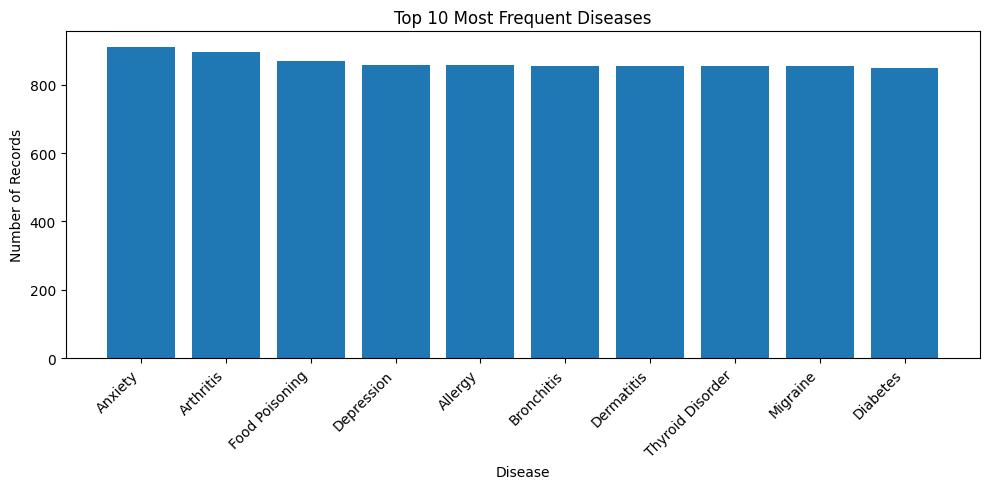

In [ ]:
# Count the occurrences of each disease
disease_counts = df["Disease"].value_counts().head(10)

# Create the bar chart
plt.figure(figsize=(10, 5))

plt.bar(disease_counts.index, disease_counts.values)

plt.title("Top 10 Most Frequent Diseases")
plt.xlabel("Disease")
plt.ylabel("Number of Records")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

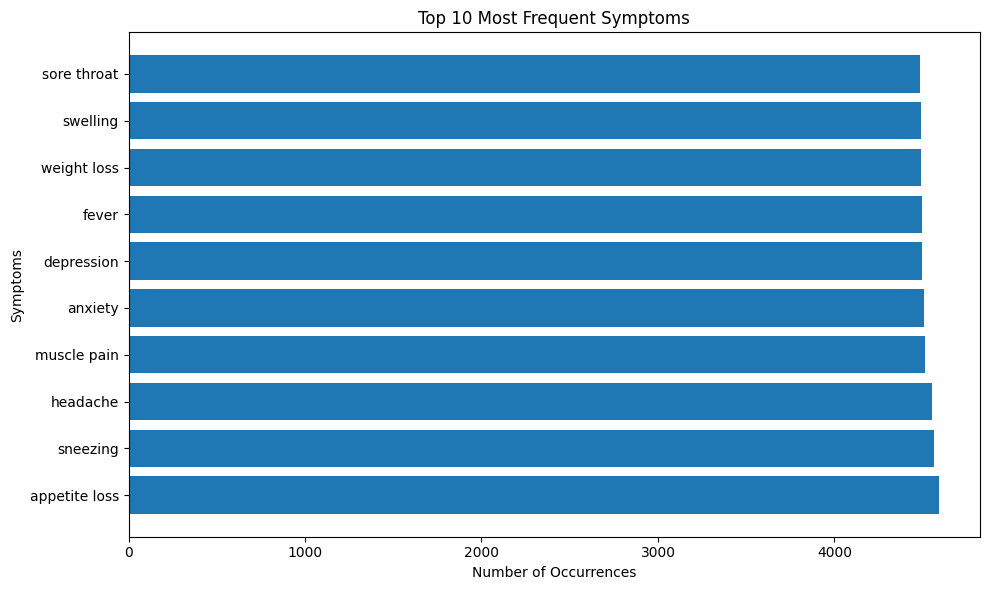

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract symptoms from the dataset
symptoms = (
    df["Symptoms"]
    .dropna()
    .astype(str)
    .str.split(",")
    .explode()
    .str.strip()
    .str.lower()
)

# Remove empty symptom values
symptoms = symptoms[symptoms != ""]

# Count the 10 most frequent symptoms
symptom_counts = symptoms.value_counts().head(10)

# Generate the horizontal bar chart
plt.figure(figsize=(10, 6))
plt.barh(symptom_counts.index, symptom_counts.values)

plt.title("Top 10 Most Frequent Symptoms")
plt.xlabel("Number of Occurrences")
plt.ylabel("Symptoms")
plt.tight_layout()
plt.show()

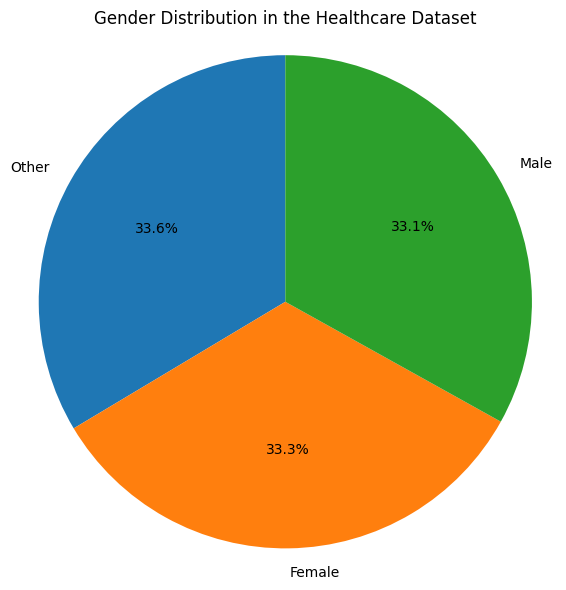

In [ ]:
# Count the records for each gender
gender_counts = df["Gender"].dropna().value_counts()

# Create the pie chart
plt.figure(figsize=(7, 7))

plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Gender Distribution in the Healthcare Dataset")
plt.axis("equal")

plt.show()

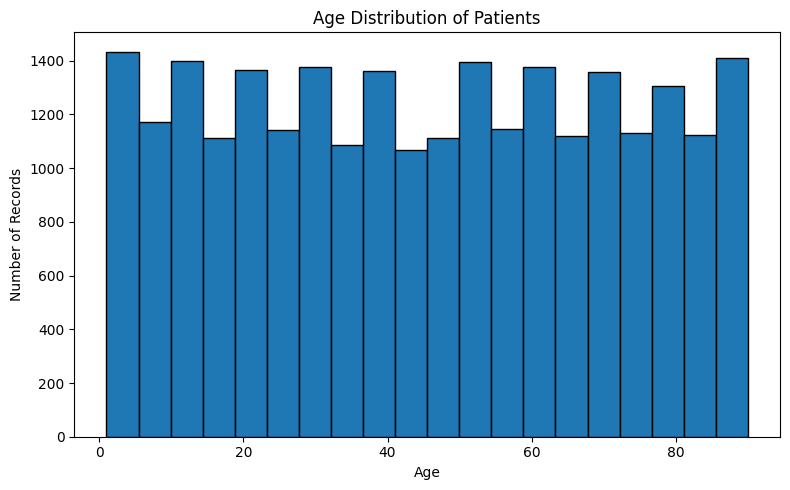

In [ ]:
#Histogram — Age Distribution
# Remove missing age values for the chart
age_data = df["Age"].dropna()

# Create the histogram
plt.figure(figsize=(8, 5))

plt.hist(age_data, bins=20, edgecolor="black")

plt.title("Age Distribution of Patients")
plt.xlabel("Age")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

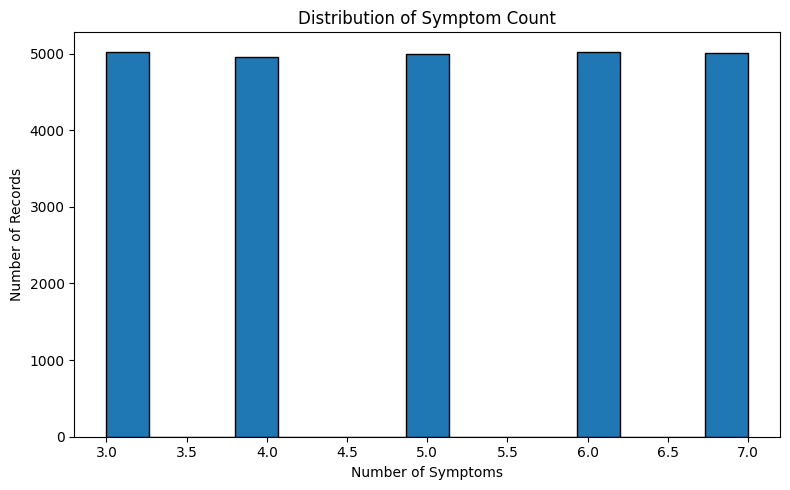

In [ ]:
#Histogram — Symptom Count Distribution
# Remove missing symptom-count values
symptom_count_data = df["Symptom_Count"].dropna()

# Create the histogram
plt.figure(figsize=(8, 5))

plt.hist(
    symptom_count_data,
    bins=15,
    edgecolor="black"
)

plt.title("Distribution of Symptom Count")
plt.xlabel("Number of Symptoms")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

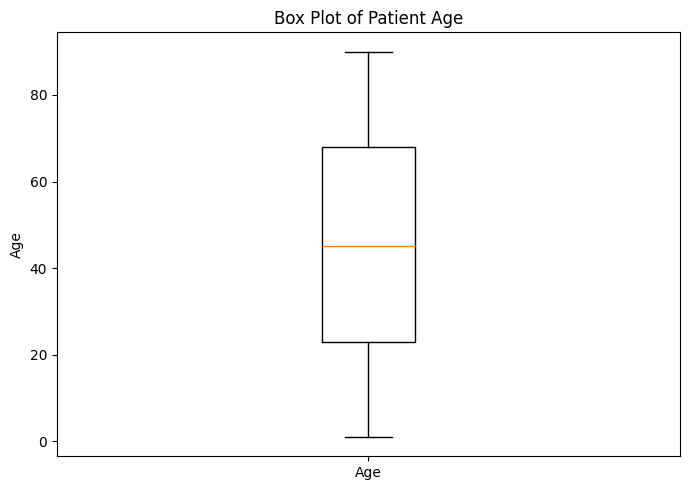

In [ ]:
#Box Plot — Age Distribution
# Select available ages
age_data = df["Age"].dropna()

# Create the box plot
plt.figure(figsize=(7, 5))

plt.boxplot(age_data)

plt.title("Box Plot of Patient Age")
plt.ylabel("Age")

plt.xticks([1], ["Age"])

plt.tight_layout()
plt.show()

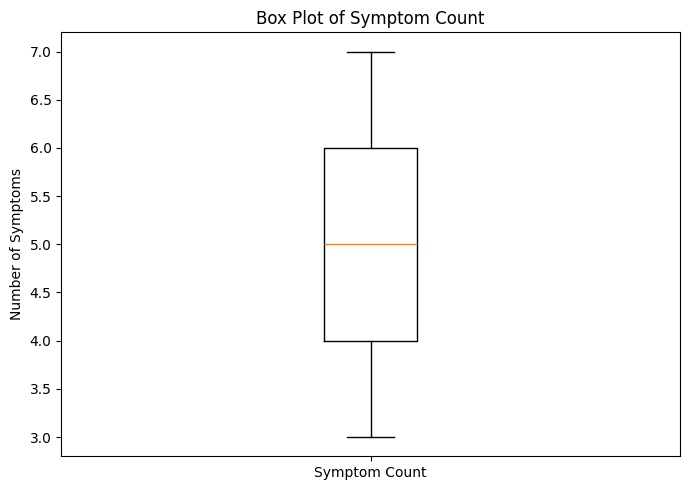

In [ ]:
#Box Plot — Symptom Count Distribution
# Select available symptom counts
symptom_count_data = df["Symptom_Count"].dropna()

# Create the box plot
plt.figure(figsize=(7, 5))

plt.boxplot(symptom_count_data)

plt.title("Box Plot of Symptom Count")
plt.ylabel("Number of Symptoms")

plt.xticks([1], ["Symptom Count"])

plt.tight_layout()
plt.show()

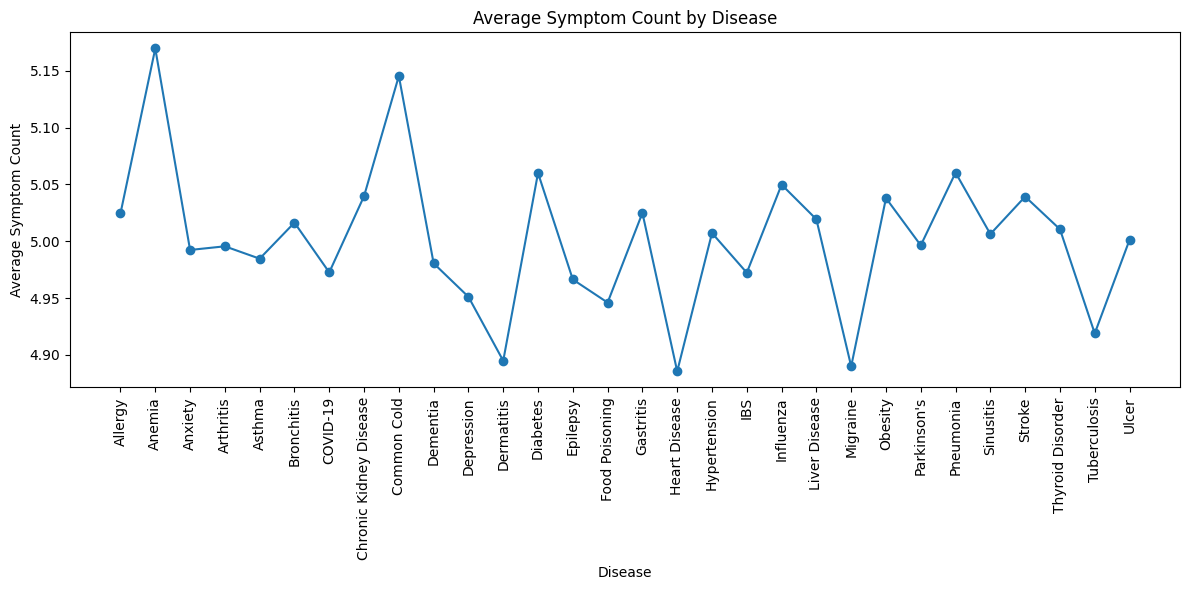

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Calculate average symptom count for each disease
avg_symptoms = df.groupby("Disease")["Symptom_Count"].mean()

# Create line chart
plt.figure(figsize=(12, 6))
plt.plot(avg_symptoms.index, avg_symptoms.values, marker="o")

plt.title("Average Symptom Count by Disease")
plt.xlabel("Disease")
plt.ylabel("Average Symptom Count")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

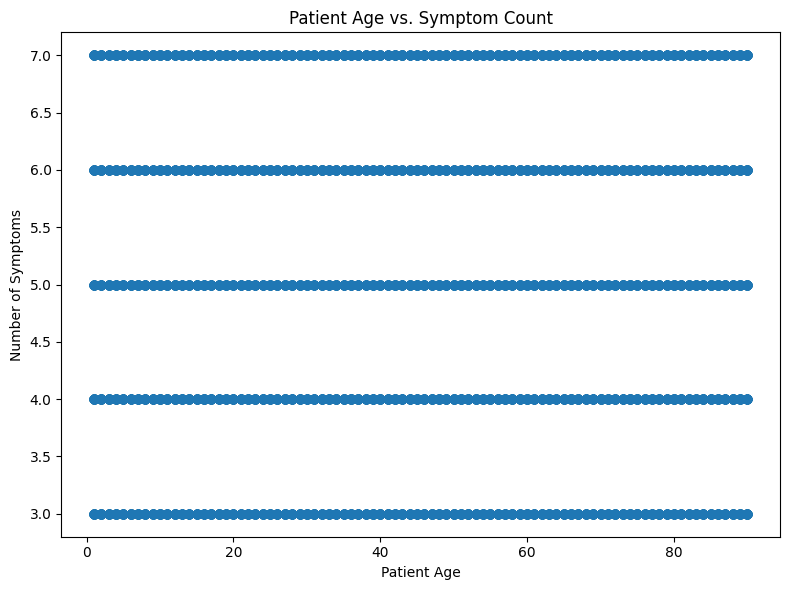

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Convert columns to numerical values
age_data = pd.to_numeric(df["Age"], errors="coerce")
symptom_data = pd.to_numeric(df["Symptom_Count"], errors="coerce")

# Remove rows with missing numerical values
plot_data = pd.DataFrame({
    "Age": age_data,
    "Symptom_Count": symptom_data
}).dropna()

# Create scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(plot_data["Age"], plot_data["Symptom_Count"])

plt.title("Patient Age vs. Symptom Count")
plt.xlabel("Patient Age")
plt.ylabel("Number of Symptoms")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np



# Convert numerical columns to numeric format
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
df["Symptom_Count"] = pd.to_numeric(df["Symptom_Count"], errors="coerce")

# Calculate key statistics
total_records = len(df)
total_attributes = len(df.columns)
total_diseases = df["Disease"].nunique()
average_age = df["Age"].mean()
minimum_age = df["Age"].min()
maximum_age = df["Age"].max()
average_symptom_count = df["Symptom_Count"].mean()

# Find the most frequent disease
disease_counts = df["Disease"].value_counts()
most_frequent_disease = disease_counts.idxmax()
most_frequent_disease_count = disease_counts.max()

# Find the most frequent symptom
symptoms = (
    df["Symptoms"]
    .dropna()
    .astype(str)
    .str.lower()
    .str.split(",")
    .explode()
    .str.strip()
)

symptoms = symptoms[symptoms != ""]
symptom_counts = symptoms.value_counts()

most_frequent_symptom = symptom_counts.idxmax()
most_frequent_symptom_count = symptom_counts.max()

# Count unique symptoms
unique_symptoms = symptoms.nunique()

# Display the results
print("=" * 45)
print("     HEALTHCARE DATASET - KEY STATISTICS")
print("=" * 45)

print(f"Total Records              : {total_records}")
print(f"Total Attributes           : {total_attributes}")
print(f"Number of Diseases         : {total_diseases}")
print(f"Unique Symptoms            : {unique_symptoms}")
print(f"Average Patient Age        : {average_age:.2f}")
print(f"Minimum Patient Age        : {minimum_age:.0f}")
print(f"Maximum Patient Age        : {maximum_age:.0f}")
print(f"Average Symptom Count      : {average_symptom_count:.2f}")
print(f"Most Frequent Disease      : {most_frequent_disease}")
print(f"Disease Record Count       : {most_frequent_disease_count}")
print(f"Most Frequent Symptom      : {most_frequent_symptom}")
print(f"Symptom Occurrence Count   : {most_frequent_symptom_count}")

print("=" * 45)

     HEALTHCARE DATASET - KEY STATISTICS
Total Records              : 24997
Total Attributes           : 7
Number of Diseases         : 30
Unique Symptoms            : 28
Average Patient Age        : 45.30
Minimum Patient Age        : 1
Maximum Patient Age        : 90
Average Symptom Count      : 5.00
Most Frequent Disease      : Anxiety
Disease Record Count       : 911
Most Frequent Symptom      : appetite loss
Symptom Occurrence Count   : 4595
